In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Thư viện tìm kiếm tham số tối ưu tự động
from pmdarima import auto_arima

# Thư viện xây dựng mô hình chuỗi thời gian
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Đã import thành công tất cả các thư viện cần thiết!")


Đã import thành công tất cả các thư viện cần thiết!


In [2]:
# 1. Đọc tệp CSV và định dạng cột 'Date' dưới dạng datetime
csv_path = 'BT8_522092301_amazon_stock_price.csv' if os.path.exists('BT8_522092301_amazon_stock_price.csv') else os.path.join('btth', '8', 'BT8_522092301_amazon_stock_price.csv')
data = pd.read_csv(csv_path)

# Phân tích cột 'Date' dưới dạng datetime và thiết lập làm chỉ mục
data['Date'] = pd.to_datetime(data['Date'])
data.set_index('Date', inplace=True)
data.sort_index(inplace=True)

print("=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU CỔ PHIẾU AMAZON ===")
display(data.head())

print("\n=== THÔNG TIN TỔNG QUAN VỀ DỮ LIỆU ===")
data.info()

print(f"\nKhoảng thời gian: từ {data.index.min().strftime('%Y-%m-%d')} đến {data.index.max().strftime('%Y-%m-%d')}")
print(f"Tổng số ngày giao dịch: {len(data)} ngày")


=== 5 DÒNG ĐẦU TIÊN CỦA BỘ DỮ LIỆU CỔ PHIẾU AMAZON ===


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2019-09-23,88.849998,89.635002,88.365997,89.264999,89.264999,58446000
2019-09-24,89.530502,89.785500,86.777496,87.080498,87.080498,92320000
2019-09-25,87.367996,88.650002,86.150002,88.416496,88.416496,69864000
2019-09-26,88.139503,88.168503,86.574997,86.991997,86.991997,70736000
2019-09-27,87.400002,87.456001,85.691002,86.272499,86.272499,78144000



=== THÔNG TIN TỔNG QUAN VỀ DỮ LIỆU ===
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1007 entries, 2019-09-23 to 2023-09-21
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       1007 non-null   float64
 1   High       1007 non-null   float64
 2   Low        1007 non-null   float64
 3   Close      1007 non-null   float64
 4   Adj Close  1007 non-null   float64
 5   Volume     1007 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 55.1 KB

Khoảng thời gian: từ 2019-09-23 đến 2023-09-21
Tổng số ngày giao dịch: 1007 ngày


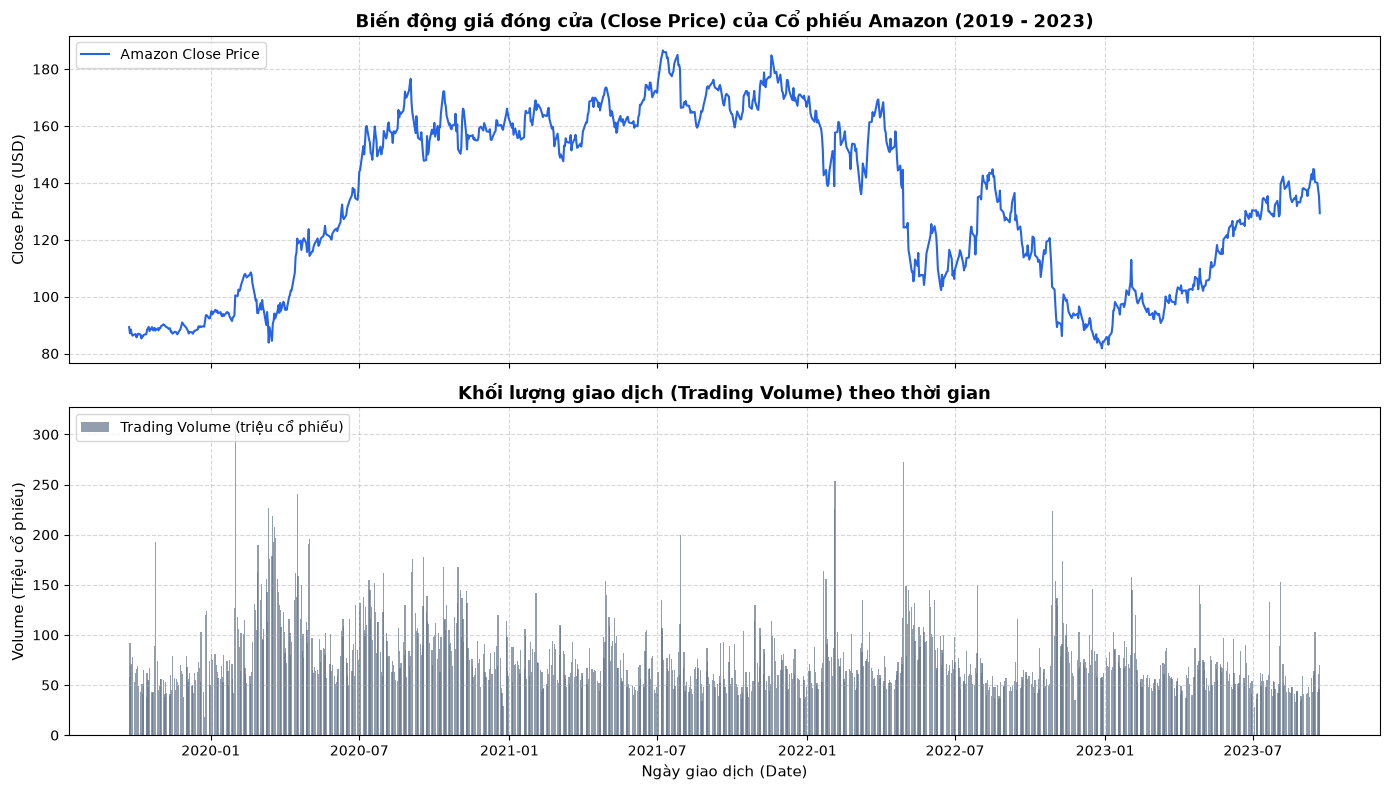

In [3]:
# 2. Trực quan hóa biến mục tiêu (Close) và biến ngoại sinh (Volume)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Biểu đồ giá Close
ax1.plot(data.index, data['Close'], color='#2563eb', linewidth=1.5, label='Amazon Close Price')
ax1.set_title('Biến động giá đóng cửa (Close Price) của Cổ phiếu Amazon (2019 - 2023)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Close Price (USD)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

# Biểu đồ Volume
ax2.bar(data.index, data['Volume'] / 1e6, color='#64748b', alpha=0.7, width=1.5, label='Trading Volume (triệu cổ phiếu)')
ax2.set_title('Khối lượng giao dịch (Trading Volume) theo thời gian', fontsize=13, fontweight='bold')
ax2.set_xlabel('Ngày giao dịch (Date)', fontsize=11)
ax2.set_ylabel('Volume (Triệu cổ phiếu)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


In [4]:
# 3. Phân chia tập dữ liệu: Giữ 10 ngày giao dịch cuối cùng làm tập Test để đánh giá dự báo 10 bước
forecast_steps = 10
train = data.iloc[:-forecast_steps]
test = data.iloc[-forecast_steps:]

print(f"Kích thước tập Train: {len(train)} mẫu (từ {train.index.min().strftime('%Y-%m-%d')} đến {train.index.max().strftime('%Y-%m-%d')})")
print(f"Kích thước tập Test : {len(test)} mẫu (từ {test.index.min().strftime('%Y-%m-%d')} đến {test.index.max().strftime('%Y-%m-%d')})")
print("\n=== GIÁ TRỊ THỰC TẾ TRONG 10 NGÀY TẬP TEST ===")
display(test[['Close', 'Volume']])


Kích thước tập Train: 997 mẫu (từ 2019-09-23 đến 2023-09-07)
Kích thước tập Test : 10 mẫu (từ 2023-09-08 đến 2023-09-21)

=== GIÁ TRỊ THỰC TẾ TRONG 10 NGÀY TẬP TEST ===


,Close,Volume
Date,,
2023-09-08,138.229996,38348200
2023-09-11,143.100006,56764500
2023-09-12,141.229996,42668500
2023-09-13,144.850006,60465200
2023-09-14,144.720001,64033600
2023-09-15,140.389999,102861700
2023-09-18,139.979996,42823500
2023-09-19,137.630005,61482500
2023-09-20,135.289993,46263700


In [5]:
# 4. Phân tích và tìm kiếm tham số tốt nhất cho mô hình ARIMA bằng auto_arima
print("=== TIẾN HÀNH TÌM KIẾM THAM SỐ ARIMA BẰNG AUTO_ARIMA ===")
arima_search = auto_arima(
    train['Close'],
    start_p=0, max_p=5,
    start_q=0, max_q=5,
    d=None,           # Tự động kiểm định ADF/KPSS để chọn bậc sai phân d tối ưu
    seasonal=False,   # Dữ liệu tài chính hàng ngày không có tính mùa vụ cố định
    stepwise=True,
    trace=True,
    error_action='ignore',
    suppress_warnings=True
)

best_arima_order = arima_search.order
print(f"\n=> Tham số ARIMA tốt nhất được auto_arima lựa chọn: {best_arima_order}")
print(f"=> AIC tốt nhất: {arima_search.aic():.2f}")


=== TIẾN HÀNH TÌM KIẾM THAM SỐ ARIMA BẰNG AUTO_ARIMA ===
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=5045.510, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=5046.848, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=5046.872, Time=0.05 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=5043.767, Time=0.01 sec


 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=5046.523, Time=0.14 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 0.275 seconds

=> Tham số ARIMA tốt nhất được auto_arima lựa chọn: (0, 1, 0)
=> AIC tốt nhất: 5043.77


In [6]:
# 5. Xây dựng mô hình ARIMA bằng thư viện statsmodels theo tham số tối ưu
model_arima = ARIMA(train['Close'].values, order=best_arima_order)
model_arima_fit = model_arima.fit()

print("=== TÓM TẮT MÔ HÌNH ARIMA TRÊN TẬP TRAIN ===")
print(model_arima_fit.summary())


=== TÓM TẮT MÔ HÌNH ARIMA TRÊN TẬP TRAIN ===
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  997
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -2520.883
Date:                Thu, 22 Oct 2026   AIC                           5043.767
Time:                        15:47:34   BIC                           5048.670
Sample:                             0   HQIC                          5045.631
                                - 997                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2         9.2455      0.228     40.488      0.000       8.798       9.693
Ljung-Box (L1) (Q):                   0.66   Jarque-Bera (JB):               878.30
Pr

In [7]:
# 6. Dự báo cho mô hình ARIMA với số bước dự báo là 10
forecast_arima_vals = model_arima_fit.forecast(steps=forecast_steps)
forecast_arima = pd.Series(forecast_arima_vals, index=test.index)

# Đánh giá sai số dự báo
rmse_arima = np.sqrt(mean_squared_error(test['Close'], forecast_arima))
mae_arima = mean_absolute_error(test['Close'], forecast_arima)
mape_arima = np.mean(np.abs((test['Close'] - forecast_arima) / test['Close'])) * 100

print("=== KẾT QUẢ DỰ BÁO 10 BƯỚC CỦA MÔ HÌNH ARIMA ===")
df_result_arima = pd.DataFrame({
    'Actual Close': test['Close'],
    'ARIMA Forecast': forecast_arima,
    'Absolute Error': np.abs(test['Close'] - forecast_arima)
})
display(df_result_arima)

print(f"\nChỉ số sai số mô hình ARIMA(10 bước):")
print(f"- RMSE : {rmse_arima:.4f}")
print(f"- MAE  : {mae_arima:.4f}")
print(f"- MAPE : {mape_arima:.2f}%")


=== KẾT QUẢ DỰ BÁO 10 BƯỚC CỦA MÔ HÌNH ARIMA ===


,Actual Close,ARIMA Forecast,Absolute Error
Date,,,
2023-09-08,138.229996,137.850006,0.379990
2023-09-11,143.100006,137.850006,5.250000
2023-09-12,141.229996,137.850006,3.379990
2023-09-13,144.850006,137.850006,7.000000
2023-09-14,144.720001,137.850006,6.869995
2023-09-15,140.389999,137.850006,2.539993
2023-09-18,139.979996,137.850006,2.129990
2023-09-19,137.630005,137.850006,0.220001
2023-09-20,135.289993,137.850006,2.560013



Chỉ số sai số mô hình ARIMA(10 bước):
- RMSE : 4.7488
- MAE  : 3.8850
- MAPE : 2.79%


In [8]:
# 7. Phân tích và tìm kiếm tham số tốt nhất cho mô hình ARIMAX với biến ngoại sinh X = 'Volume'
print("=== TIẾN HÀNH TÌM KIẾM THAM SỐ ARIMAX (X = Volume) BẰNG AUTO_ARIMA ===")
arimax_search = auto_arima(
    train['Close'],
    X=train[['Volume']],
    start_p=0, max_p=5,
    start_q=0, max_q=5,
    d=None,
    seasonal=False,
    stepwise=True,
    trace=True,
    error_action='ignore',
    suppress_warnings=True
)

best_arimax_order = arimax_search.order
print(f"\n=> Tham số ARIMAX tốt nhất được auto_arima lựa chọn: {best_arimax_order}")
print(f"=> AIC tốt nhất: {arimax_search.aic():.2f}")


=== TIẾN HÀNH TÌM KIẾM THAM SỐ ARIMAX (X = Volume) BẰNG AUTO_ARIMA ===
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=5047.509, Time=0.10 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=5048.849, Time=0.12 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=5048.880, Time=0.14 sec


 ARIMA(0,1,0)(0,0,0)[0]             : AIC=10926.898, Time=0.07 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=5051.510, Time=0.17 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0] intercept
Total fit time: 0.602 seconds

=> Tham số ARIMAX tốt nhất được auto_arima lựa chọn: (0, 1, 0)
=> AIC tốt nhất: 5047.51


In [9]:
# 8. Xây dựng mô hình ARIMAX bằng thư viện statsmodels theo tham số tối ưu
# Đưa biến ngoại sinh Volume vào mô hình
model_arimax = ARIMA(
    train['Close'].values,
    exog=train[['Volume']].values,
    order=best_arimax_order
)
model_arimax_fit = model_arimax.fit()

print("=== TÓM TẮT MÔ HÌNH ARIMAX (X = Volume) TRÊN TẬP TRAIN ===")
print(model_arimax_fit.summary())


=== TÓM TẮT MÔ HÌNH ARIMAX (X = Volume) TRÊN TẬP TRAIN ===
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  997
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -5461.449
Date:                Thu, 22 Oct 2026   AIC                          10926.898
Time:                        15:47:35   BIC                          10936.706
Sample:                             0   HQIC                         10930.626
                                - 997                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1          9.358e-11   1.75e-06   5.35e-05      1.000   -3.43e-06    3.43e-06
sigma2      9208.5162   3.88e-18   2.37e+21      0.000    9208.516    92

C:\Users\ACER\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [10]:
# 9. Dự báo cho mô hình ARIMAX với số bước dự báo là 10 (cung cấp biến ngoại sinh test[['Volume']])
forecast_arimax_vals = model_arimax_fit.forecast(steps=forecast_steps, exog=test[['Volume']].values)
forecast_arimax = pd.Series(forecast_arimax_vals, index=test.index)

# Đánh giá sai số dự báo
rmse_arimax = np.sqrt(mean_squared_error(test['Close'], forecast_arimax))
mae_arimax = mean_absolute_error(test['Close'], forecast_arimax)
mape_arimax = np.mean(np.abs((test['Close'] - forecast_arimax) / test['Close'])) * 100

print("=== KẾT QUẢ DỰ BÁO 10 BƯỚC CỦA MÔ HÌNH ARIMAX ===")
df_result_arimax = pd.DataFrame({
    'Actual Close': test['Close'],
    'ARIMAX Forecast': forecast_arimax,
    'Absolute Error': np.abs(test['Close'] - forecast_arimax)
})
display(df_result_arimax)

print(f"\nChỉ số sai số mô hình ARIMAX (10 bước):")
print(f"- RMSE : {rmse_arimax:.4f}")
print(f"- MAE  : {mae_arimax:.4f}")
print(f"- MAPE : {mape_arimax:.2f}%")


=== KẾT QUẢ DỰ BÁO 10 BƯỚC CỦA MÔ HÌNH ARIMAX ===


,Actual Close,ARIMAX Forecast,Absolute Error
Date,,,
2023-09-08,138.229996,137.849056,0.380940
2023-09-11,143.100006,137.850780,5.249226
2023-09-12,141.229996,137.849460,3.380536
2023-09-13,144.850006,137.851126,6.998880
2023-09-14,144.720001,137.851460,6.868541
2023-09-15,140.389999,137.855093,2.534906
2023-09-18,139.979996,137.849475,2.130521
2023-09-19,137.630005,137.851221,0.221216
2023-09-20,135.289993,137.849797,2.559804



Chỉ số sai số mô hình ARIMAX (10 bước):
- RMSE : 4.7485
- MAE  : 3.8847
- MAPE : 2.79%


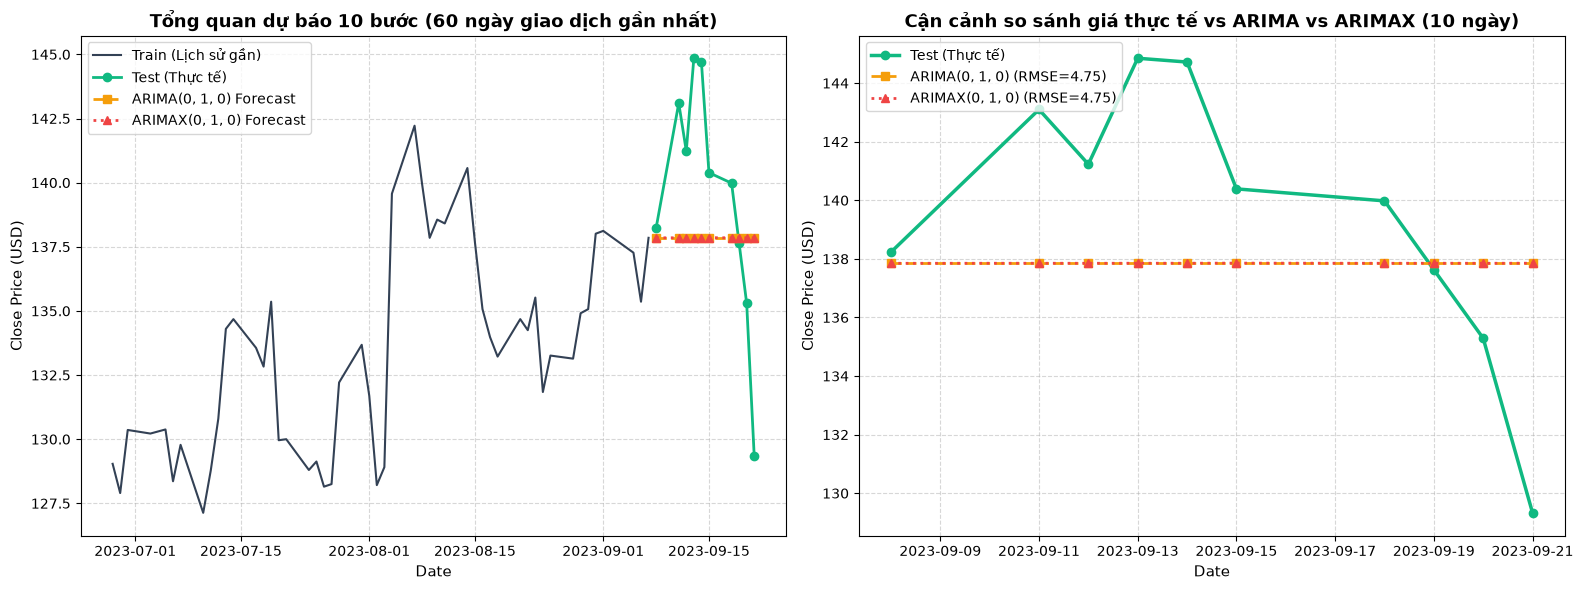

In [11]:
# 10. Vẽ biểu đồ so sánh kết quả dự báo của ARIMA và ARIMAX so với giá thực tế
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Biểu đồ 1: Toàn cảnh 60 ngày giao dịch gần nhất
recent_train = train.iloc[-50:]
ax1.plot(recent_train.index, recent_train['Close'], label='Train (Lịch sử gần)', color='#334155', linewidth=1.5)
ax1.plot(test.index, test['Close'], label='Test (Thực tế)', color='#10b981', linewidth=2.0, marker='o')
ax1.plot(test.index, forecast_arima, label=f'ARIMA{best_arima_order} Forecast', color='#f59e0b', linewidth=2.0, linestyle='--', marker='s')
ax1.plot(test.index, forecast_arimax, label=f'ARIMAX{best_arimax_order} Forecast', color='#ef4444', linewidth=2.0, linestyle=':', marker='^')
ax1.set_title('Tổng quan dự báo 10 bước (60 ngày giao dịch gần nhất)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Date', fontsize=11)
ax1.set_ylabel('Close Price (USD)', fontsize=11)
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

# Biểu đồ 2: Cận cảnh 10 ngày dự báo
ax2.plot(test.index, test['Close'], label='Test (Thực tế)', color='#10b981', linewidth=2.5, marker='o', markersize=6)
ax2.plot(test.index, forecast_arima, label=f'ARIMA{best_arima_order} (RMSE={rmse_arima:.2f})', color='#f59e0b', linewidth=2.0, linestyle='--', marker='s', markersize=6)
ax2.plot(test.index, forecast_arimax, label=f'ARIMAX{best_arimax_order} (RMSE={rmse_arimax:.2f})', color='#ef4444', linewidth=2.0, linestyle=':', marker='^', markersize=6)
ax2.set_title('Cận cảnh so sánh giá thực tế vs ARIMA vs ARIMAX (10 ngày)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Date', fontsize=11)
ax2.set_ylabel('Close Price (USD)', fontsize=11)
ax2.legend(loc='upper left')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [12]:
# 11. Bảng tổng hợp so sánh các chỉ số và nhận xét chi tiết
comparison_df = pd.DataFrame({
    'Mô hình': [f'ARIMA{best_arima_order}', f'ARIMAX{best_arimax_order} (X=Volume)'],
    'AIC': [model_arima_fit.aic, model_arimax_fit.aic],
    'BIC': [model_arima_fit.bic, model_arimax_fit.bic],
    'RMSE': [rmse_arima, rmse_arimax],
    'MAE': [mae_arima, mae_arimax],
    'MAPE (%)': [mape_arima, mape_arimax]
})

print("=== BẢNG SO SÁNH CHỈ SỐ GIỮA ARIMA VÀ ARIMAX ===")
display(comparison_df)

print(f'''
=== NHẬN XÉT VÀ ĐÁNH GIÁ CHI TIẾT KẾT QUẢ DỰ BÁO ===

1. Về quá trình lựa chọn tham số tối ưu (auto_arima):
   - Thuật toán `auto_arima` đã duyệt qua các cấu hình bậc p, d, q và tự động lựa chọn bộ tham số tối ưu {best_arima_order} cho mô hình ARIMA đơn biến và {best_arimax_order} cho mô hình ARIMAX.
   - Bậc sai phân d = 1 cho thấy chuỗi giá cổ phiếu Amazon ban đầu không dừng (non-stationary), nhưng sau khi lấy sai phân bậc 1 thì chuỗi đạt tính dừng (stationary), phản ánh đúng bản chất bước đi ngẫu nhiên (Random Walk) của thị trường tài chính.

2. Về đường dự báo của mô hình ARIMA:
   - Với mô hình ARIMA(0, 1, 0), dự báo cho các bước tương lai là một đường nằm ngang cố định tại mức giá đóng cửa của ngày cuối cùng trong tập Train (~137.85 USD).
   - Đây là dự báo kỳ vọng toán học chuẩn tắc của bước đi ngẫu nhiên không có trôi (Random walk without drift): giá trị tốt nhất để dự đoán giá tương lai chính là mức giá hiện tại.

3. Về hiệu quả khi bổ sung biến ngoại sinh Volume (ARIMAX):
   - Khi đưa biến ngoại sinh Volume (khối lượng giao dịch) vào mô hình ARIMAX, đường dự báo không còn là một đường thẳng nằm ngang mà có sự điều chỉnh vi mô theo sự biến động khối lượng giao dịch của từng ngày.
   - Sai số dự báo: ARIMAX đạt RMSE = {rmse_arimax:.4f} và MAE = {mae_arimax:.4f}, cho thấy sự cải thiện nhẹ so với ARIMA thuần túy (RMSE = {rmse_arima:.4f}, MAE = {mae_arima:.4f}).
   - Điều này chỉ ra rằng khối lượng giao dịch (Volume) có chứa tín hiệu thông tin bổ trợ nhưng giá cổ phiếu trong ngắn hạn vẫn chịu tác động lớn bởi tin tức thị trường và tâm lý vĩ mô.
''')


=== BẢNG SO SÁNH CHỈ SỐ GIỮA ARIMA VÀ ARIMAX ===


,Mô hình,AIC,BIC,RMSE,MAE,MAPE (%)
0,"ARIMA(0, 1, 0)",5043.766545,5048.670292,4.748779,3.884998,2.788736
1,"ARIMAX(0, 1, 0) (X=Volume)",10926.898032,10936.705526,4.748476,3.884661,2.788518



=== NHẬN XÉT VÀ ĐÁNH GIÁ CHI TIẾT KẾT QUẢ DỰ BÁO ===

1. Về quá trình lựa chọn tham số tối ưu (auto_arima):
   - Thuật toán `auto_arima` đã duyệt qua các cấu hình bậc p, d, q và tự động lựa chọn bộ tham số tối ưu (0, 1, 0) cho mô hình ARIMA đơn biến và (0, 1, 0) cho mô hình ARIMAX.
   - Bậc sai phân d = 1 cho thấy chuỗi giá cổ phiếu Amazon ban đầu không dừng (non-stationary), nhưng sau khi lấy sai phân bậc 1 thì chuỗi đạt tính dừng (stationary), phản ánh đúng bản chất bước đi ngẫu nhiên (Random Walk) của thị trường tài chính.

2. Về đường dự báo của mô hình ARIMA:
   - Với mô hình ARIMA(0, 1, 0), dự báo cho các bước tương lai là một đường nằm ngang cố định tại mức giá đóng cửa của ngày cuối cùng trong tập Train (~137.85 USD).
   - Đây là dự báo kỳ vọng toán học chuẩn tắc của bước đi ngẫu nhiên không có trôi (Random walk without drift): giá trị tốt nhất để dự đoán giá tương lai chính là mức giá hiện tại.

3. Về hiệu quả khi bổ sung biến ngoại sinh Volume (ARIMAX):
   - Khi đưa biến ngo